### Persiapan Lingkungan dan Pemuatan Metadata (kamus_data.md)
Pada tahap awal memuat library utama serta membaca kamus_data.md dan berkas metadata latih serta uji (klasifikasi_train_meta.csv dan klasifikasi_test_meta.csv). Langkah ini penting untuk memastikan definisi variabel, nama kolom identitas/label/lini produksi, serta struktur berkas .npz sesuai dengan dokumentasi dataset sebelum dilakukan analisis lebih lanjut.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Atur seed agar hasil yang melibatkan sampling acak konsisten
SEED = 42
np.random.seed(SEED)

# Tampilkan isi kamus_data.md sebagai acuan struktur data
kamus_path = DATA_DIR / "kamus_data.md"
if kamus_path.exists():
  print("=== KAMUS DATA ===")
  print(kamus_path.read_text(encoding="utf-8"))

# Muat metadata train dan test
train_meta = pd.read_csv(DATA_DIR / "klasifikasi_train_meta.csv")
test_meta = pd.read_csv(DATA_DIR / "klasifikasi_test_meta.csv")

print("Shape train_meta:", train_meta.shape)
print("Shape test_meta :", test_meta.shape)
print("\nKolom train_meta:", train_meta.columns.tolist())
print("Kolom test_meta :", test_meta.columns.tolist())
display(train_meta.head())

=== KAMUS DATA ===
# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur dan tidak dijamin bebas salah.

## Tugas 2: rul_train.csv.gz dan rul_test.csv.gz

Log per siklus untuk mesin press fiktif. Data latih b

,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal
3,3,U696502,A,siang,M06,B085,noda
4,4,U272751,B,siang,M08,B106,normal


### Inspeksi Struktur File .npz (klasifikasi_train.npz & klasifikasi_test.npz)

Data gambar dan sinyal/spektrum sensor pada tugas klasifikasi disimpan dalam berkas .npz. Kita perlu memeriksa daftar key, bentuk (shape), dan tipe data (dtype) di dalamnya agar proses indeksasi antar baris metadata dan array modalitas tidak tertukar.

In [22]:
npz_train = np.load(DATA_DIR / "klasifikasi_train.npz", allow_pickle=True)
npz_test = np.load(DATA_DIR / "klasifikasi_test.npz", allow_pickle=True)

print("Keys di klasifikasi_train.npz:")
for key in npz_train.files:
  arr = npz_train[key]
  print(f"  - {key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nKeys di klasifikasi_test.npz:")
for key in npz_test.files:
  arr = npz_test[key]
  print(f"  - {key}: shape={arr.shape}, dtype={arr.dtype}")

Keys di klasifikasi_train.npz:
  - gambar: shape=(48000, 64, 64), dtype=uint8
  - sensor: shape=(48000, 3, 128), dtype=float16

Keys di klasifikasi_test.npz:
  - gambar: shape=(16000, 64, 64), dtype=uint8
  - sensor: shape=(16000, 3, 128), dtype=float16


### Distribusi Tujuh Kelas pada Data Latih

Klasifikasi produk terdiri dari tujuh kelas: normal, gores, noda, retak, gelembung, las_dingin, dan kontaminasi. Mengecek jumlah dan persentase tiap kelas membantu mengetahui apakah dataset seimbang atau timpang (imbalanced), yang nantinya berpengaruh pada strategi pelatihan dan evaluasi berbasis macro-F1.

,jumlah,persentase (%)
kelas,,
normal,23888,49.77
gores,5623,11.71
noda,4773,9.94
retak,3606,7.51
gelembung,3430,7.15
las_dingin,4323,9.01
kontaminasi,2357,4.91


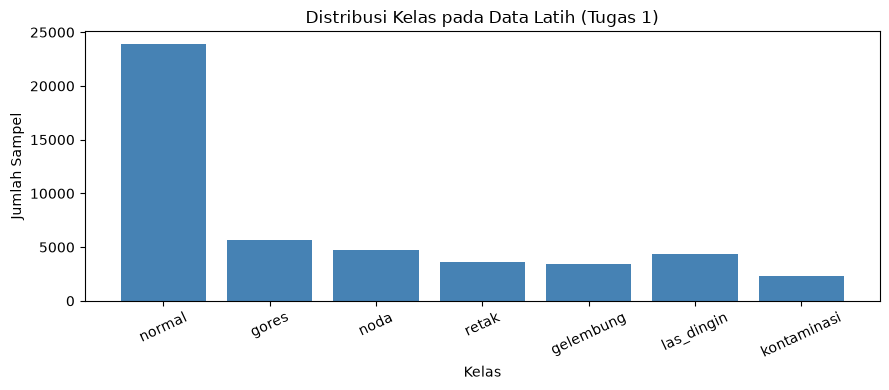

In [23]:
# Sesuaikan nama kolom label sesuai kamus_data.md (misalnya 'kelas' atau 'label')
LABEL_COL = "kelas"

CLASSES = [
    "normal",
    "gores",
    "noda",
    "retak",
    "gelembung",
    "las_dingin",
    "kontaminasi",
]

counts = train_meta[LABEL_COL].value_counts().reindex(CLASSES, fill_value=0)
pct = (counts / len(train_meta) * 100).round(2)

df_dist = pd.DataFrame({"jumlah": counts, "persentase (%)": pct})
display(df_dist)

plt.figure(figsize=(9, 4))
plt.bar(df_dist.index, df_dist["jumlah"], color="steelblue")
plt.title("Distribusi Kelas pada Data Latih (Tugas 1)")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Sampel")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Analisis Rekaman Sensor yang Hilang (Missing Sensor Recordings)

Sebagian unit pada lini produksi dapat memiliki rekaman sensor yang hilang atau tidak terekam. Pada bagian ini kita menghitung persentase sensor yang hilang di data latih maupun data uji, serta melihat apakah kemunculannya berkaitan dengan kelas tertentu atau lini produksi tertentu. Informasi ini akan menjadi dasar untuk penanganan missing modality pada tahap berikutnya.

In [24]:
sensors_tr = np.asarray(npz_train["sensor"], dtype=np.float32)
sensors_te = np.asarray(npz_test["sensor"], dtype=np.float32)

# True jika ada minimal satu NaN pada kanal/waktu sensor di sampel tersebut
train_meta["sensor_missing"] = np.isnan(sensors_tr).any(axis=(1, 2))
test_meta["sensor_missing"] = np.isnan(sensors_te).any(axis=(1, 2))

print(
    f"Missing sensor di Train: {train_meta['sensor_missing'].mean()*100:.2f}%"
)
print(f"Missing sensor di Test : {test_meta['sensor_missing'].mean()*100:.2f}%")

print("\nPersentase missing sensor per kelas (Train):")
print((train_meta.groupby("kelas")["sensor_missing"].mean() * 100).round(2))

print("\nPersentase missing sensor per lini produksi (Train & Test):")
print(
    pd.DataFrame({
        "train_%": (
            train_meta.groupby("lini")["sensor_missing"].mean() * 100
        ).round(2),
        "test_%": (
            test_meta.groupby("lini")["sensor_missing"].mean() * 100
        ).round(2),
    })
)

Missing sensor di Train: 8.05%
Missing sensor di Test : 8.11%

Persentase missing sensor per kelas (Train):
kelas
gelembung      8.02
gores          8.50
kontaminasi    7.13
las_dingin     7.66
noda           7.81
normal         8.09
retak          8.49
Name: sensor_missing, dtype: float64

Persentase missing sensor per lini produksi (Train & Test):
      train_%  test_%
lini                 
A        8.09    8.24
B        7.91    8.03


### Perbedaan Antar Lini Produksi dan Train-Test Differences

Membandingkan komposisi lini produksi (A dan B), distribusi kelas antar lini, serta statistik dasar gambar dan sinyal sensor antar lini untuk melihat potensi domain shift.

In [25]:
print("=== Distribusi Kelas per Lini Produksi (Train) ===")
display(pd.crosstab(train_meta["lini"], train_meta["kelas"]))

print("=== Proporsi Lini Produksi: Train vs Test (%) ===")
display(
    pd.DataFrame({
        "train_%": (train_meta["lini"].value_counts(normalize=True) * 100).round(
            2
        ),
        "test_%": (test_meta["lini"].value_counts(normalize=True) * 100).round(
            2
        ),
    })
)

imgs_tr = npz_train["gambar"]
line_stats = []
for lini_val, grp in train_meta.groupby("lini"):
  idx = grp["indeks"].to_numpy()
  sub_img = imgs_tr[idx].astype(np.float32)
  sub_sig = sensors_tr[idx]
  line_stats.append({
      "lini": lini_val,
      "n_sampel": len(idx),
      "img_mean": float(np.mean(sub_img)),
      "img_std": float(np.std(sub_img)),
      "sig_mean_non_nan": float(np.nanmean(sub_sig)),
      "sig_std_non_nan": float(np.nanstd(sub_sig)),
  })
display(pd.DataFrame(line_stats))

=== Distribusi Kelas per Lini Produksi (Train) ===


kelas,gelembung,gores,kontaminasi,las_dingin,noda,normal,retak
lini,,,,,,,
A,2577,4231,1777,3250,3568,17862,2699
B,853,1392,580,1073,1205,6026,907


=== Proporsi Lini Produksi: Train vs Test (%) ===


,train_%,test_%
lini,,
A,74.92,39.96
B,25.07,60.04


,lini,n_sampel,img_mean,img_std,sig_mean_non_nan,sig_std_non_nan
0,A,35964,139.790695,15.248120,63.195446,83.473915
1,B,12036,111.731911,19.081274,63.835999,84.427322


### Contoh Visualisasi Tiap Kelas (Gambar + 3 Kanal Sensor)
Menampilkan satu contoh sampel untuk tiap kelas berupa citra permukaan (64x64) dan tiga kanal sensor tekan (suhu, getaran, arus sepanjang 128 titik) agar pola tiap jenis cacat mudah diamati.

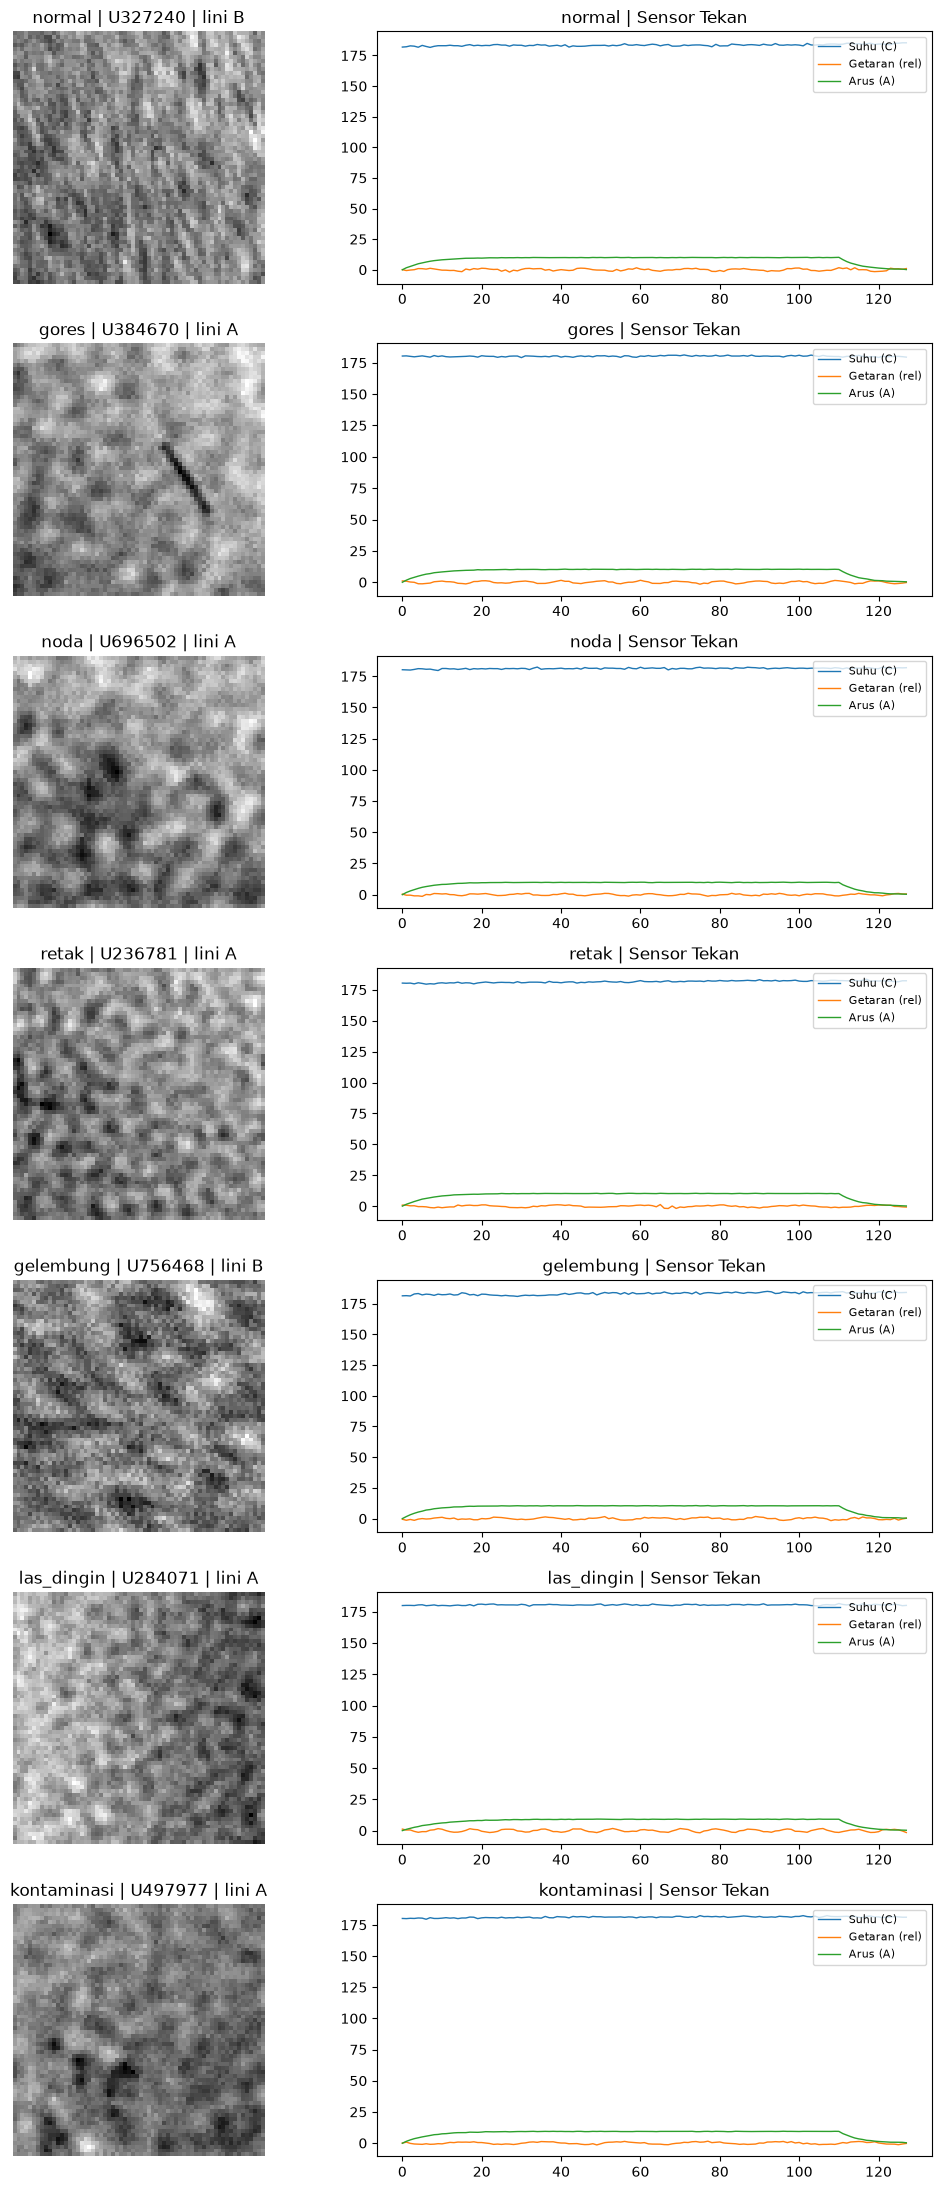

In [26]:
kanal_names = ["Suhu (C)", "Getaran (rel)", "Arus (A)"]
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(11, 22))

for r_idx, cls in enumerate(CLASSES):
  sub = train_meta[train_meta["kelas"] == cls]
  ax_img, ax_sig = axes[r_idx, 0], axes[r_idx, 1]

  if len(sub) == 0:
    ax_img.set_title(f"{cls} - Kosong")
    ax_img.axis("off")
    ax_sig.axis("off")
    continue

  row = sub.iloc[0]
  i = int(row["indeks"])
  img = imgs_tr[i]
  sig = sensors_tr[i]  # (3, 128)

  ax_img.imshow(img, cmap="gray" if img.ndim == 2 else None)
  ax_img.set_title(f"{cls} | {row['id_unit']} | lini {row['lini']}")
  ax_img.axis("off")

  if np.isnan(sig).all():
    ax_sig.text(0.5, 0.5, "Sensor Tidak Terekam (NaN)", ha="center", va="center")
    ax_sig.set_title(f"{cls} | Sensor Missing")
  else:
    for c in range(sig.shape[0]):
      ax_sig.plot(sig[c], label=kanal_names[c], linewidth=1.0)
    ax_sig.set_title(f"{cls} | Sensor Tekan")
    ax_sig.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

### Persiapan Dataset Mini, Penanganan NaN, dan Split Validasi Cepat
Sebelum melatih model penuh, kita menyiapkan PyTorch Dataset untuk modalitas gambar (64x64, dinormalisasi ke [0, 1]) dan sensor (3x128, nilai NaN diisi 0.0 agar tidak menghasilkan NaN saat komputasi gradien), memetakan 7 label kelas menjadi angka 0..6, serta membagi data latih menjadi subset train dan validation (stratified) agar pengecekan kurva belajar berjalan cepat.

In [27]:
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Set seed PyTorch untuk reproduksibilitas
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Perangkat yang dipakai:", device)

CLASSES = [
    "normal",
    "gores",
    "noda",
    "retak",
    "gelembung",
    "las_dingin",
    "kontaminasi",
]
label2idx = {c: i for i, c in enumerate(CLASSES)}

imgs_all = npz_train["gambar"]  # (N, 64, 64) uint8
sigs_all = np.asarray(
    npz_train["sensor"], dtype=np.float32
)  # (N, 3, 128) float16 -> float32
y_all = train_meta["kelas"].map(label2idx).to_numpy()
indices_all = train_meta["indeks"].to_numpy()

# Ambil subset cepat dulu untuk sanity check (misal 4.000 sampel; ubah ke len(y_all) jika ingin penuh)
SUBSET_N = min(4000, len(y_all))
sub_idx, _ = train_test_split(
    np.arange(len(y_all)),
    train_size=SUBSET_N,
    stratify=y_all,
    random_state=SEED,
)

tr_idx, va_idx = train_test_split(
    sub_idx, test_size=0.2, stratify=y_all[sub_idx], random_state=SEED
)


class MultimodalDefectDataset(Dataset):

  def __init__(self, row_positions, imgs, sigs, labels, row_to_npz_idx):
    self.row_positions = np.asarray(row_positions)
    self.imgs = imgs
    self.sigs = sigs
    self.labels = labels
    self.row_to_npz_idx = row_to_npz_idx

  def __len__(self):
    return len(self.row_positions)

  def __getitem__(self, pos):
    r = self.row_positions[pos]
    npz_i = int(self.row_to_npz_idx[r])

    img = self.imgs[npz_i].astype(np.float32) / 255.0
    if img.ndim == 2:
      img = img[None, :, :]  # (1, 64, 64)
    else:
      img = np.transpose(img, (2, 0, 1))

    sig = np.nan_to_num(self.sigs[npz_i], nan=0.0).astype(
        np.float32
    )  # (3, 128)
    label = int(self.labels[r])

    return (
        torch.tensor(img, dtype=torch.float32),
        torch.tensor(sig, dtype=torch.float32),
        torch.tensor(label, dtype=torch.long),
    )


train_ds = MultimodalDefectDataset(
    tr_idx, imgs_all, sigs_all, y_all, indices_all
)
val_ds = MultimodalDefectDataset(va_idx, imgs_all, sigs_all, y_all, indices_all)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

print(f"Jumlah train sanity: {len(train_ds)} | val sanity: {len(val_ds)}")

Perangkat yang dipakai: cpu
Jumlah train sanity: 3200 | val sanity: 800


### Model Multimodal Ringan untuk Sanity Check
Kita membuat arsitektur prototype ringan yang menggabungkan encoder gambar (Conv2d sederhana) dan encoder sinyal (Conv1d sederhana), lalu menggabungkan fitur keduanya untuk memprediksi 7 kelas. Model ini sengaja dibuat ringkas agar pengujian overfit satu batch dan kurva belajar berjalan cepat.

In [28]:
class QuickMultimodalNet(nn.Module):

  def __init__(self, num_classes=7):
    super().__init__()
    self.img_enc = nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),  # 32x32
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
    )
    self.sig_enc = nn.Sequential(
        nn.Conv1d(3, 16, kernel_size=5, padding=2),
        nn.ReLU(),
        nn.MaxPool1d(2),  # 64
        nn.Conv1d(16, 32, kernel_size=5, padding=2),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
        nn.Flatten(),
    )
    self.head = nn.Sequential(
        nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, num_classes)
    )

  def forward(self, img, sig):
    f_img = self.img_enc(img)
    f_sig = self.sig_enc(sig)
    fused = torch.cat([f_img, f_sig], dim=1)
    return self.head(fused)

### Sanity Check 1: Overfit Satu Batch
Kita mengambil satu batch berisi 16 sampel dan melatihnya selama 150 iterasi. Targetnya adalah melihat loss turun drastis mendekati 0 dan akurasi naik hingga 1.00 (100%), yang menjadi bukti bahwa aliran gradien dan pembaruan bobot bekerja tanpa kendala.

Step   1 | Loss: 2.4289 | Acc: 0.00%
Step  25 | Loss: 1.3753 | Acc: 43.75%
Step  50 | Loss: 1.3160 | Acc: 43.75%
Step 100 | Loss: 1.3062 | Acc: 43.75%
Step 150 | Loss: 1.2959 | Acc: 43.75%


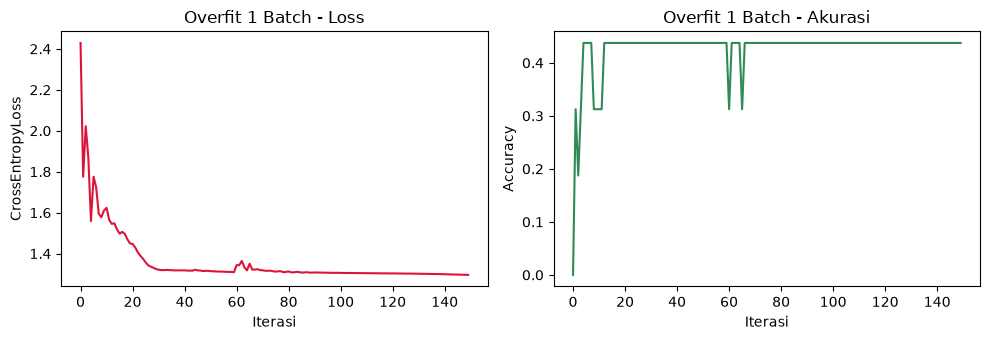

In [29]:
overfit_model = QuickMultimodalNet(num_classes=len(CLASSES)).to(device)
optimizer_of = torch.optim.Adam(overfit_model.parameters(), lr=3e-3)
criterion = nn.CrossEntropyLoss()

batch_img, batch_sig, batch_y = next(iter(train_loader))
batch_img = batch_img[:16].to(device)
batch_sig = batch_sig[:16].to(device)
batch_y = batch_y[:16].to(device)

of_losses, of_accs = [], []
overfit_model.train()
for step in range(1, 151):
  optimizer_of.zero_grad()
  logits = overfit_model(batch_img, batch_sig)
  loss = criterion(logits, batch_y)
  loss.backward()
  optimizer_of.step()

  preds = logits.argmax(dim=1)
  acc = (preds == batch_y).float().mean().item()
  of_losses.append(loss.item())
  of_accs.append(acc)

  if step in [1, 25, 50, 100, 150]:
    print(f"Step {step:3d} | Loss: {loss.item():.4f} | Acc: {acc*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(of_losses, color="crimson")
axes[0].set_title("Overfit 1 Batch - Loss")
axes[0].set_xlabel("Iterasi")
axes[0].set_ylabel("CrossEntropyLoss")

axes[1].plot(of_accs, color="seagreen")
axes[1].set_title("Overfit 1 Batch - Akurasi")
axes[1].set_xlabel("Iterasi")
axes[1].set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

### Sanity Check 2: Kurva Belajar (Learning Curves)
Setelah memastikan model mampu menghafal satu batch, kita melatihnya selama beberapa epoch (misalnya 8 epoch sebagai pengecekan awal) pada train subset dan mengevaluasinya pada validation subset menggunakan loss serta macro-F1 (metrik utama Tugas 1). Kurva ini membantu melihat apakah proses belajar berjalan stabil atau perlu penyesuaian learning rate / normalisasi.

Epoch  1/8 | Train Loss: 1.7912 | Val Loss: 1.6413 | Val Macro-F1: 0.0949
Epoch  2/8 | Train Loss: 1.5996 | Val Loss: 1.6044 | Val Macro-F1: 0.0949
Epoch  3/8 | Train Loss: 1.5946 | Val Loss: 1.6146 | Val Macro-F1: 0.0949
Epoch  4/8 | Train Loss: 1.5917 | Val Loss: 1.6064 | Val Macro-F1: 0.0949
Epoch  5/8 | Train Loss: 1.5863 | Val Loss: 1.5950 | Val Macro-F1: 0.0949
Epoch  6/8 | Train Loss: 1.5975 | Val Loss: 1.6008 | Val Macro-F1: 0.0949
Epoch  7/8 | Train Loss: 1.5948 | Val Loss: 1.6027 | Val Macro-F1: 0.0949
Epoch  8/8 | Train Loss: 1.5888 | Val Loss: 1.5904 | Val Macro-F1: 0.0949


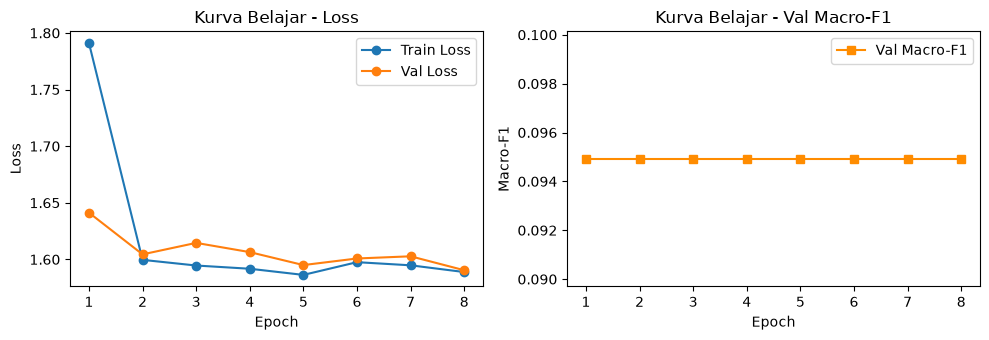

In [31]:
lc_model = QuickMultimodalNet(num_classes=len(CLASSES)).to(device)
optimizer_lc = torch.optim.Adam(lc_model.parameters(), lr=1e-3)

EPOCHS = 8
train_losses, val_losses, val_f1s = [], [], []

for epoch in range(1, EPOCHS + 1):
  lc_model.train()
  tr_loss_sum = 0.0
  for b_img, b_sig, b_y in train_loader:
    b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
    optimizer_lc.zero_grad()
    out = lc_model(b_img, b_sig)
    loss = criterion(out, b_y)
    loss.backward()
    optimizer_lc.step()
    tr_loss_sum += loss.item() * len(b_y)

  tr_loss = tr_loss_sum / len(train_ds)

  lc_model.eval()
  va_loss_sum = 0.0
  all_preds, all_targets = [], []
  with torch.no_grad():
    for b_img, b_sig, b_y in val_loader:
      b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
      out = lc_model(b_img, b_sig)
      loss = criterion(out, b_y)
      va_loss_sum += loss.item() * len(b_y)
      all_preds.append(out.argmax(dim=1).cpu().numpy())
      all_targets.append(b_y.cpu().numpy())

  va_loss = va_loss_sum / len(val_ds)
  y_pred_cat = np.concatenate(all_preds)
  y_true_cat = np.concatenate(all_targets)
  macro_f1 = f1_score(y_true_cat, y_pred_cat, average="macro", zero_division=0)

  train_losses.append(tr_loss)
  val_losses.append(va_loss)
  val_f1s.append(macro_f1)
  print(
      f"Epoch {epoch:2d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Val Loss:"
      f" {va_loss:.4f} | Val Macro-F1: {macro_f1:.4f}"
  )

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
epochs_range = range(1, EPOCHS + 1)
axes[0].plot(epochs_range, train_losses, marker="o", label="Train Loss")
axes[0].plot(epochs_range, val_losses, marker="o", label="Val Loss")
axes[0].set_title("Kurva Belajar - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    epochs_range, val_f1s, marker="s", color="darkorange", label="Val Macro-F1"
)
axes[1].set_title("Kurva Belajar - Val Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()

plt.tight_layout()
plt.show()

### Baseline Image-Only
Melatih classifier berbasis CNN ringan yang hanya menerima input citra 64x64, lalu mencatat Val Loss dan Val Macro-F1 sebagai tolok ukur modalitas gambar saja.

In [32]:
class ImageOnlyBaseline(nn.Module):

  def __init__(self, num_classes=7):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),  # 32x32
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),  # 16x16
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Linear(64, num_classes),
    )

  def forward(self, img, sig=None):
    return self.net(img)


def evaluate_model(model, loader, criterion, device, mode="both"):
  model.eval()
  total_loss = 0.0
  preds_list, targets_list = [], []
  with torch.no_grad():
    for b_img, b_sig, b_y in loader:
      b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
      if mode == "img":
        out = model(b_img, None)
      elif mode == "sig":
        out = model(None, b_sig)
      else:
        out = model(b_img, b_sig)
      loss = criterion(out, b_y)
      total_loss += loss.item() * len(b_y)
      preds_list.append(out.argmax(dim=1).cpu().numpy())
      targets_list.append(b_y.cpu().numpy())
  avg_loss = total_loss / len(loader.dataset)
  y_pred = np.concatenate(preds_list)
  y_true = np.concatenate(targets_list)
  macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
  return avg_loss, macro_f1


img_model = ImageOnlyBaseline(num_classes=len(CLASSES)).to(device)
opt_img = torch.optim.AdamW(img_model.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS_BASE = 8
best_img_f1 = 0.0
for epoch in range(1, EPOCHS_BASE + 1):
  img_model.train()
  tr_loss = 0.0
  for b_img, _, b_y in train_loader:
    b_img, b_y = b_img.to(device), b_y.to(device)
    opt_img.zero_grad()
    out = img_model(b_img, None)
    loss = criterion(out, b_y)
    loss.backward()
    opt_img.step()
    tr_loss += loss.item() * len(b_y)
  tr_loss /= len(train_ds)
  va_loss, va_f1 = evaluate_model(
      img_model, val_loader, criterion, device, mode="img"
  )
  best_img_f1 = max(best_img_f1, va_f1)
  print(
      f"[Image-Only] Epoch {epoch:2d}/{EPOCHS_BASE} | Train Loss: {tr_loss:.4f}"
      f" | Val Loss: {va_loss:.4f} | Val Macro-F1: {va_f1:.4f}"
  )

[Image-Only] Epoch  1/8 | Train Loss: 1.6746 | Val Loss: 1.6047 | Val Macro-F1: 0.0949
[Image-Only] Epoch  2/8 | Train Loss: 1.5741 | Val Loss: 1.5713 | Val Macro-F1: 0.0949
[Image-Only] Epoch  3/8 | Train Loss: 1.5673 | Val Loss: 1.5758 | Val Macro-F1: 0.0949
[Image-Only] Epoch  4/8 | Train Loss: 1.5677 | Val Loss: 1.6043 | Val Macro-F1: 0.0949
[Image-Only] Epoch  5/8 | Train Loss: 1.5638 | Val Loss: 1.5807 | Val Macro-F1: 0.0949
[Image-Only] Epoch  6/8 | Train Loss: 1.5590 | Val Loss: 1.6317 | Val Macro-F1: 0.1074
[Image-Only] Epoch  7/8 | Train Loss: 1.5567 | Val Loss: 1.5612 | Val Macro-F1: 0.0949
[Image-Only] Epoch  8/8 | Train Loss: 1.5498 | Val Loss: 1.5727 | Val Macro-F1: 0.0949


### Baseline Signal-Only
Melatih classifier berbasis Conv1d + BatchNorm1d yang hanya menerima input sinyal sensor (3, 128), lalu membandingkan hasilnya dengan baseline gambar.

In [33]:
class SignalOnlyBaseline(nn.Module):

  def __init__(self, num_classes=7):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv1d(3, 32, kernel_size=5, padding=2),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.MaxPool1d(2),  # 64
        nn.Conv1d(32, 64, kernel_size=5, padding=2),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.MaxPool1d(2),  # 32
        nn.Conv1d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
        nn.Flatten(),
        nn.Linear(128, num_classes),
    )

  def forward(self, img=None, sig=None):
    return self.net(sig)


sig_model = SignalOnlyBaseline(num_classes=len(CLASSES)).to(device)
opt_sig = torch.optim.AdamW(sig_model.parameters(), lr=1e-3, weight_decay=1e-4)

best_sig_f1 = 0.0
for epoch in range(1, EPOCHS_BASE + 1):
  sig_model.train()
  tr_loss = 0.0
  for _, b_sig, b_y in train_loader:
    b_sig, b_y = b_sig.to(device), b_y.to(device)
    opt_sig.zero_grad()
    out = sig_model(None, b_sig)
    loss = criterion(out, b_y)
    loss.backward()
    opt_sig.step()
    tr_loss += loss.item() * len(b_y)
  tr_loss /= len(train_ds)
  va_loss, va_f1 = evaluate_model(
      sig_model, val_loader, criterion, device, mode="sig"
  )
  best_sig_f1 = max(best_sig_f1, va_f1)
  print(
      f"[Signal-Only] Epoch {epoch:2d}/{EPOCHS_BASE} | Train Loss:"
      f" {tr_loss:.4f} | Val Loss: {va_loss:.4f} | Val Macro-F1: {va_f1:.4f}"
  )

print("\n=== Ringkasan Baseline (Best Val Macro-F1) ===")
print(f"Image-Only  : {best_img_f1:.4f}")
print(f"Signal-Only : {best_sig_f1:.4f}")

[Signal-Only] Epoch  1/8 | Train Loss: 1.5950 | Val Loss: 1.5882 | Val Macro-F1: 0.1855
[Signal-Only] Epoch  2/8 | Train Loss: 1.4494 | Val Loss: 1.4477 | Val Macro-F1: 0.1774
[Signal-Only] Epoch  3/8 | Train Loss: 1.4200 | Val Loss: 1.5524 | Val Macro-F1: 0.1300
[Signal-Only] Epoch  4/8 | Train Loss: 1.4213 | Val Loss: 1.4415 | Val Macro-F1: 0.1835
[Signal-Only] Epoch  5/8 | Train Loss: 1.4166 | Val Loss: 1.4967 | Val Macro-F1: 0.1447
[Signal-Only] Epoch  6/8 | Train Loss: 1.4122 | Val Loss: 4.9462 | Val Macro-F1: 0.0393
[Signal-Only] Epoch  7/8 | Train Loss: 1.4145 | Val Loss: 1.6913 | Val Macro-F1: 0.0949
[Signal-Only] Epoch  8/8 | Train Loss: 1.3993 | Val Loss: 1.4741 | Val Macro-F1: 0.1619

=== Ringkasan Baseline (Best Val Macro-F1) ===
Image-Only  : 0.1074
Signal-Only : 0.1855


### Standarisasi Sensor (Fit di Train) & Dataset Multimodal Terstandarisasi
Kita menghitung rata-rata (mean) dan standar deviasi (std) tiap kanal sensor (0, 1, 2) hanya pada sampel latih (tr_idx) dengan np.nanmean dan np.nanstd agar nilai NaN tidak merusak statistik. Setelah dinormalisasi, NaN diubah menjadi 0.0 (yang kini setara dengan nilai rata-rata kanal setelah z-score).

In [34]:
# Hitung mean & std tiap kanal sensor hanya dari data train split (anti data leakage)
train_sigs_raw = sigs_all[indices_all[tr_idx]]  # (N_tr, 3, 128)
sig_mean = np.nanmean(train_sigs_raw, axis=(0, 2), keepdims=True).astype(
    np.float32
)
sig_std = np.nanstd(train_sigs_raw, axis=(0, 2), keepdims=True).astype(
    np.float32
)
sig_std = np.where(sig_std < 1e-6, 1.0, sig_std)

sigs_norm_all = ((sigs_all - sig_mean) / sig_std).astype(np.float32)

train_ds_norm = MultimodalDefectDataset(
    tr_idx, imgs_all, sigs_norm_all, y_all, indices_all
)
val_ds_norm = MultimodalDefectDataset(
    va_idx, imgs_all, sigs_norm_all, y_all, indices_all
)

train_loader_norm = DataLoader(train_ds_norm, batch_size=64, shuffle=True)
val_loader_norm = DataLoader(val_ds_norm, batch_size=64, shuffle=False)

print(
    "Normalisasi sinyal siap | mean per kanal:",
    np.round(sig_mean.squeeze(), 4),
)
print("Normalisasi sinyal siap | std  per kanal:", np.round(sig_std.squeeze(), 4))

Normalisasi sinyal siap | mean per kanal: [ 1.816238e+02 -7.000000e-04  8.457400e+00]
Normalisasi sinyal siap | std  per kanal: [1.1254 0.7941 2.9544]


### Definisi Encoder Gambar (CNN) & Encoder Sinyal (1D-CNN + GRU)
ImageCNNEncoder: mengekstrak representasi fitur spasial dari citra 64x64 menjadi vektor berdimensi embed_dim (128).

SignalHybridEncoder (1D-CNN + GRU): mengekstrak pola lokal lintas waktu lewat Conv1d, lalu menangkap dinamika sekuensial jangka panjang sepanjang 128 langkah tekan menggunakan GRU dua arah/unidirectional, dan memproyeksikannya ke dimensi embed_dim (128).

MultimodalEncoderPair: membungkus kedua encoder tersebut

In [35]:
class ImageCNNEncoder(nn.Module):

  def __init__(self, embed_dim=128):
    super().__init__()
    self.features = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.SiLU(),
        nn.MaxPool2d(2),  # 32x32
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.SiLU(),
        nn.MaxPool2d(2),  # 16x16
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.SiLU(),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
    )
    self.proj = nn.Sequential(
        nn.Linear(128, embed_dim), nn.LayerNorm(embed_dim), nn.SiLU()
    )

  def forward(self, img):
    h = self.features(img)
    return self.proj(h)


class SignalConvGRUEncoder(nn.Module):

  def __init__(self, in_channels=3, gru_hidden=64, embed_dim=128):
    super().__init__()
    self.conv = nn.Sequential(
        nn.Conv1d(in_channels, 32, kernel_size=5, padding=2),
        nn.BatchNorm1d(32),
        nn.SiLU(),
        nn.MaxPool1d(2),  # 64
        nn.Conv1d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm1d(64),
        nn.SiLU(),
        nn.MaxPool1d(2),  # 32
    )
    self.gru = nn.GRU(
        input_size=64, hidden_size=gru_hidden, num_layers=1, batch_first=True
    )
    self.proj = nn.Sequential(
        nn.Linear(gru_hidden, embed_dim), nn.LayerNorm(embed_dim), nn.SiLU()
    )

  def forward(self, sig):
    # sig: (B, 3, 128) -> conv: (B, 64, 32) -> transpose: (B, 32, 64)
    x = self.conv(sig).transpose(1, 2)
    _, h_n = self.gru(x)  # h_n: (1, B, gru_hidden)
    last_h = h_n[-1]  # (B, gru_hidden)
    return self.proj(last_h)


class MultimodalPairNet(nn.Module):

  def __init__(self, num_classes=7, embed_dim=128):
    super().__init__()
    self.img_encoder = ImageCNNEncoder(embed_dim=embed_dim)
    self.sig_encoder = SignalConvGRUEncoder(
        in_channels=3, gru_hidden=64, embed_dim=embed_dim
    )
    self.classifier = nn.Sequential(
        nn.Dropout(0.2), nn.Linear(embed_dim * 2, num_classes)
    )

  def forward(self, img, sig):
    z_img = self.img_encoder(img)
    z_sig = self.sig_encoder(sig)
    z_cat = torch.cat([z_img, z_sig], dim=1)
    return self.classifier(z_cat)

### Latih & Evaluasi Pasangan Encoder
Melatih MultimodalPairNet pada data terstandarisasi selama beberapa epoch dan mencatat Best Val Macro-F1 untuk dibandingkan dengan baseline Image-Only (0.1074) dan Signal-Only (0.1855) dari Nomor 8.

In [36]:
pair_model = MultimodalPairNet(num_classes=len(CLASSES), embed_dim=128).to(
    device
)
optimizer_pair = torch.optim.AdamW(
    pair_model.parameters(), lr=1e-3, weight_decay=1e-4
)

EPOCHS_PAIR = 8
best_pair_f1 = 0.0
pair_val_f1s = []

for epoch in range(1, EPOCHS_PAIR + 1):
  pair_model.train()
  tr_loss = 0.0
  for b_img, b_sig, b_y in train_loader_norm:
    b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
    optimizer_pair.zero_grad()
    out = pair_model(b_img, b_sig)
    loss = criterion(out, b_y)
    loss.backward()
    optimizer_pair.step()
    tr_loss += loss.item() * len(b_y)

  tr_loss /= len(train_ds_norm)
  va_loss, va_f1 = evaluate_model(
      pair_model, val_loader_norm, criterion, device, mode="both"
  )
  pair_val_f1s.append(va_f1)
  best_pair_f1 = max(best_pair_f1, va_f1)
  print(
      f"[CNN + Conv1D-GRU] Epoch {epoch:2d}/{EPOCHS_PAIR} | Train Loss:"
      f" {tr_loss:.4f} | Val Loss: {va_loss:.4f} | Val Macro-F1: {va_f1:.4f}"
  )

print(f"\nBest Val Macro-F1 (CNN + Conv1D-GRU): {best_pair_f1:.4f}")

[CNN + Conv1D-GRU] Epoch  1/8 | Train Loss: 1.6090 | Val Loss: 1.5946 | Val Macro-F1: 0.0949
[CNN + Conv1D-GRU] Epoch  2/8 | Train Loss: 1.5730 | Val Loss: 1.5724 | Val Macro-F1: 0.0949
[CNN + Conv1D-GRU] Epoch  3/8 | Train Loss: 1.5387 | Val Loss: 1.5138 | Val Macro-F1: 0.1263
[CNN + Conv1D-GRU] Epoch  4/8 | Train Loss: 1.4375 | Val Loss: 1.4445 | Val Macro-F1: 0.2159
[CNN + Conv1D-GRU] Epoch  5/8 | Train Loss: 1.3766 | Val Loss: 1.3868 | Val Macro-F1: 0.2947
[CNN + Conv1D-GRU] Epoch  6/8 | Train Loss: 1.2789 | Val Loss: 2.1009 | Val Macro-F1: 0.1720
[CNN + Conv1D-GRU] Epoch  7/8 | Train Loss: 1.2326 | Val Loss: 1.2281 | Val Macro-F1: 0.4133
[CNN + Conv1D-GRU] Epoch  8/8 | Train Loss: 1.1529 | Val Loss: 1.1764 | Val Macro-F1: 0.4110

Best Val Macro-F1 (CNN + Conv1D-GRU): 0.4133


### Definisi Arsitektur Late Fusion dan Cross-Attention Fusion
Kita menggunakan ulang ImageCNNEncoder dan SignalConvGRUEncoder (atau bagian conv sinyalnya) agar perbedaan performa murni berasal dari cara penggabungan (fusion) modalitas gambar dan sensor.

In [37]:
class LateFusionNet(nn.Module):

  def __init__(self, num_classes=7, embed_dim=128, alpha_img=0.5):
    super().__init__()
    self.alpha_img = alpha_img
    self.img_encoder = ImageCNNEncoder(embed_dim=embed_dim)
    self.sig_encoder = SignalConvGRUEncoder(
        in_channels=3, gru_hidden=64, embed_dim=embed_dim
    )
    self.img_head = nn.Linear(embed_dim, num_classes)
    self.sig_head = nn.Linear(embed_dim, num_classes)

  def forward(self, img, sig):
    z_img = self.img_encoder(img)
    z_sig = self.sig_encoder(sig)
    logits_img = self.img_head(z_img)
    logits_sig = self.sig_head(z_sig)
    return self.alpha_img * logits_img + (1.0 - self.alpha_img) * logits_sig


class CrossAttentionFusionNet(nn.Module):

  def __init__(self, num_classes=7, embed_dim=128, num_heads=4):
    super().__init__()
    self.img_encoder = ImageCNNEncoder(embed_dim=embed_dim)
    self.sig_seq_enc = nn.Sequential(
        nn.Conv1d(3, 32, kernel_size=5, padding=2),
        nn.BatchNorm1d(32),
        nn.SiLU(),
        nn.MaxPool1d(2),  # 64
        nn.Conv1d(32, embed_dim, kernel_size=3, padding=1),
        nn.BatchNorm1d(embed_dim),
        nn.SiLU(),
        nn.MaxPool1d(2),  # 32 langkah waktu -> token (B, 32, embed_dim)
    )
    self.cross_attn = nn.MultiheadAttention(
        embed_dim=embed_dim, num_heads=num_heads, dropout=0.1, batch_first=True
    )
    self.norm = nn.LayerNorm(embed_dim)
    self.classifier = nn.Sequential(
        nn.Dropout(0.2),
        nn.Linear(embed_dim * 2, 128),
        nn.SiLU(),
        nn.Linear(128, num_classes),
    )

  def forward(self, img, sig):
    z_img = self.img_encoder(img)  # (B, D)
    kv_img = z_img.unsqueeze(1)  # (B, 1, D) sebagai Key & Value dari gambar

    q_sig = self.sig_seq_enc(sig).transpose(1, 2)  # (B, 32, D) sebagai Query
    attn_out, _ = self.cross_attn(
        query=q_sig, key=kv_img, value=kv_img
    )  # (B, 32, D)
    attn_pooled = self.norm(
        (q_sig + attn_out).mean(dim=1)
    )  # pooled konteks ter-atensi (B, D)

    fused = torch.cat([z_img, attn_pooled], dim=1)  # (B, 2*D)
    return self.classifier(fused)

### Pelatihan & Tabel Perbandingan Strategi Fusi
Kita latih kedua model selama 8 epoch dengan optimizer dan learning rate yang setara, mencatat riwayat Val Macro-F1 serta Best Val Macro-F1, lalu menyajikannya dalam tabel perbandingan dan grafik kurva.

[Late Fusion] Epoch  1/8 | Train Loss: 1.6004 | Val Loss: 1.5868 | Val Macro-F1: 0.0949
[Late Fusion] Epoch  2/8 | Train Loss: 1.5623 | Val Loss: 1.5655 | Val Macro-F1: 0.0949
[Late Fusion] Epoch  3/8 | Train Loss: 1.4830 | Val Loss: 1.4563 | Val Macro-F1: 0.1728
[Late Fusion] Epoch  4/8 | Train Loss: 1.3946 | Val Loss: 1.4457 | Val Macro-F1: 0.2154
[Late Fusion] Epoch  5/8 | Train Loss: 1.2841 | Val Loss: 1.2827 | Val Macro-F1: 0.3380
[Late Fusion] Epoch  6/8 | Train Loss: 1.2153 | Val Loss: 1.1803 | Val Macro-F1: 0.3942
[Late Fusion] Epoch  7/8 | Train Loss: 1.1463 | Val Loss: 1.1456 | Val Macro-F1: 0.4041
[Late Fusion] Epoch  8/8 | Train Loss: 1.0700 | Val Loss: 1.4629 | Val Macro-F1: 0.4178
[Cross-Attention] Epoch  1/8 | Train Loss: 1.5485 | Val Loss: 1.4622 | Val Macro-F1: 0.2189
[Cross-Attention] Epoch  2/8 | Train Loss: 1.3886 | Val Loss: 1.3611 | Val Macro-F1: 0.2086
[Cross-Attention] Epoch  3/8 | Train Loss: 1.3366 | Val Loss: 1.3226 | Val Macro-F1: 0.2615
[Cross-Attention] Ep

,Strategi Fusi,Best Val Macro-F1
0,Feature Concatenation,0.4133
1,Late Fusion (Logit Avg),0.4178
2,Cross-Attention Fusion,0.4704


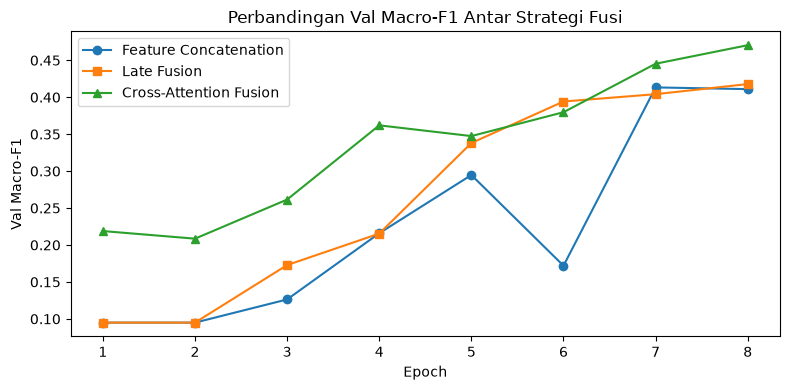

In [39]:
def train_fusion_model(
    model,
    train_loader,
    val_loader,
    criterion,
    device,
    epochs=8,
    lr=1e-3,
    name="Fusion",
):
  opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
  best_f1 = 0.0
  best_loss = float("inf")
  f1_history = []

  for ep in range(1, epochs + 1):
    model.train()
    tr_loss = 0.0
    for b_img, b_sig, b_y in train_loader:
      b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
      opt.zero_grad()
      out = model(b_img, b_sig)
      loss = criterion(out, b_y)
      loss.backward()
      opt.step()
      tr_loss += loss.item() * len(b_y)
    tr_loss /= len(train_loader.dataset)

    va_loss, va_f1 = evaluate_model(
        model, val_loader, criterion, device, mode="both"
    )
    f1_history.append(va_f1)
    if va_f1 > best_f1:
      best_f1 = va_f1
      best_loss = va_loss
    print(
        f"[{name}] Epoch {ep:2d}/{epochs} | Train Loss: {tr_loss:.4f} | Val"
        f" Loss: {va_loss:.4f} | Val Macro-F1: {va_f1:.4f}"
    )

  return best_f1, best_loss, f1_history


torch.manual_seed(SEED)
late_model = LateFusionNet(
    num_classes=len(CLASSES), embed_dim=128, alpha_img=0.5
).to(device)
late_best_f1, late_best_loss, late_hist = train_fusion_model(
    late_model,
    train_loader_norm,
    val_loader_norm,
    criterion,
    device,
    epochs=8,
    lr=1e-3,
    name="Late Fusion",
)

torch.manual_seed(SEED)
ca_model = CrossAttentionFusionNet(
    num_classes=len(CLASSES), embed_dim=128, num_heads=4
).to(device)
ca_best_f1, ca_best_loss, ca_hist = train_fusion_model(
    ca_model,
    train_loader_norm,
    val_loader_norm,
    criterion,
    device,
    epochs=8,
    lr=1e-3,
    name="Cross-Attention",
)

df_fusion_cmp = pd.DataFrame([
    {
        "Strategi Fusi": "Feature Concatenation",
        "Best Val Macro-F1": round(best_pair_f1, 4),
    },
    {
        "Strategi Fusi": "Late Fusion (Logit Avg)",
        "Best Val Macro-F1": round(late_best_f1, 4),
    },
    {
        "Strategi Fusi": "Cross-Attention Fusion",
        "Best Val Macro-F1": round(ca_best_f1, 4),
    },
])
display(df_fusion_cmp)

plt.figure(figsize=(8, 4))
ep_range = range(1, 9)
plt.plot(ep_range, pair_val_f1s, marker="o", label="Feature Concatenation")
plt.plot(ep_range, late_hist, marker="s", label="Late Fusion")
plt.plot(ep_range, ca_hist, marker="^", label="Cross-Attention Fusion")
plt.title("Perbandingan Val Macro-F1 Antar Strategi Fusi")
plt.xlabel("Epoch")
plt.ylabel("Val Macro-F1")
plt.legend()
plt.tight_layout()
plt.show()

### F1-Score per Kelas: Image Head vs Signal Head vs Late Fusion
Kita menjalankan inference pada val_loader_norm menggunakan late_model untuk mengambil logits_img dan logits_sig secara terpisah, lalu menghitung skor F1 per kelas (average=None) untuk Image Only, Signal Only, dan Late Fusion. Ini membantu menjawab kelas mana yang lebih kuat dikenali lewat citra visual (gores, noda, retak, dll.) dan kelas mana yang lebih kuat lewat sinyal sensor.

In [40]:
from sklearn.metrics import classification_report, f1_score

late_model.eval()
y_true_val = []
pred_img_only, pred_sig_only, pred_late_fused = [], [], []

with torch.no_grad():
  for b_img, b_sig, b_y in val_loader_norm:
    b_img, b_sig = b_img.to(device), b_sig.to(device)
    z_img = late_model.img_encoder(b_img)
    z_sig = late_model.sig_encoder(b_sig)

    logits_img = late_model.img_head(z_img)
    logits_sig = late_model.sig_head(z_sig)
    logits_fuse = late_model.alpha_img * logits_img + (
        1.0 - late_model.alpha_img
    ) * logits_sig

    y_true_val.append(b_y.numpy())
    pred_img_only.append(logits_img.argmax(dim=1).cpu().numpy())
    pred_sig_only.append(logits_sig.argmax(dim=1).cpu().numpy())
    pred_late_fused.append(logits_fuse.argmax(dim=1).cpu().numpy())

y_true_val = np.concatenate(y_true_val)
pred_img_only = np.concatenate(pred_img_only)
pred_sig_only = np.concatenate(pred_sig_only)
pred_late_fused = np.concatenate(pred_late_fused)

f1_per_cls_img = f1_score(
    y_true_val, pred_img_only, average=None, labels=range(len(CLASSES)), zero_division=0
)
f1_per_cls_sig = f1_score(
    y_true_val, pred_sig_only, average=None, labels=range(len(CLASSES)), zero_division=0
)
f1_per_cls_late = f1_score(
    y_true_val, pred_late_fused, average=None, labels=range(len(CLASSES)), zero_division=0
)

df_mod_class = pd.DataFrame({
    "Kelas": CLASSES,
    "Jumlah Val": [int((y_true_val == i).sum()) for i in range(len(CLASSES))],
    "F1 Image Head": np.round(f1_per_cls_img, 4),
    "F1 Signal Head": np.round(f1_per_cls_sig, 4),
    "F1 Late Fusion": np.round(f1_per_cls_late, 4),
})
df_mod_class["Modalitas Unggul"] = np.where(
    df_mod_class["F1 Image Head"] > df_mod_class["F1 Signal Head"],
    "Gambar",
    np.where(
        df_mod_class["F1 Signal Head"] > df_mod_class["F1 Image Head"],
        "Sensor",
        "Setara",
    ),
)

display(df_mod_class)

,Kelas,Jumlah Val,F1 Image Head,F1 Signal Head,F1 Late Fusion,Modalitas Unggul
0,normal,398,0.4178,0.7073,0.4985,Sensor
1,gores,94,0.0000,0.0000,0.0000,Setara
2,noda,80,0.1584,0.0000,0.1935,Gambar
3,retak,60,0.0000,0.4192,0.4685,Sensor
4,gelembung,57,0.0000,0.6923,0.6923,Sensor
5,las_dingin,72,0.0000,0.8859,0.9296,Sensor
6,kontaminasi,39,0.1054,0.0000,0.1425,Gambar


### F1-Score per Kelas pada Cross-Attention Fusion & Visualisasi
Kita juga menghitung F1 per kelas dari ca_model (CrossAttentionFusionNet) dan memplot perbandingan F1 per kelas antar modalitas/model agar pola keunggulan tiap modalitas per kelas mudah dibaca pada grafik dan laporan.

,Kelas,Jumlah Val,F1 Image Head,F1 Signal Head,F1 Late Fusion,F1 Cross-Attention,Modalitas Unggul
0,normal,398,0.4178,0.7073,0.4985,0.7318,Sensor
1,gores,94,0.0000,0.0000,0.0000,0.0000,Setara
2,noda,80,0.1584,0.0000,0.1935,0.1136,Gambar
3,retak,60,0.0000,0.4192,0.4685,0.5567,Sensor
4,gelembung,57,0.0000,0.6923,0.6923,0.5495,Sensor
5,las_dingin,72,0.0000,0.8859,0.9296,0.7840,Sensor
6,kontaminasi,39,0.1054,0.0000,0.1425,0.5574,Gambar



Classification Report Detail (Cross-Attention Fusion pada Validation):
              precision    recall  f1-score   support

      normal     0.5913    0.9598    0.7318       398
       gores     0.0000    0.0000    0.0000        94
        noda     0.6250    0.0625    0.1136        80
       retak     0.7297    0.4500    0.5567        60
   gelembung     0.7353    0.4386    0.5495        57
  las_dingin     0.9245    0.6806    0.7840        72
 kontaminasi     0.7727    0.4359    0.5574        39

    accuracy                         0.6312       800
   macro avg     0.6255    0.4325    0.4704       800
weighted avg     0.5847    0.6312    0.5541       800



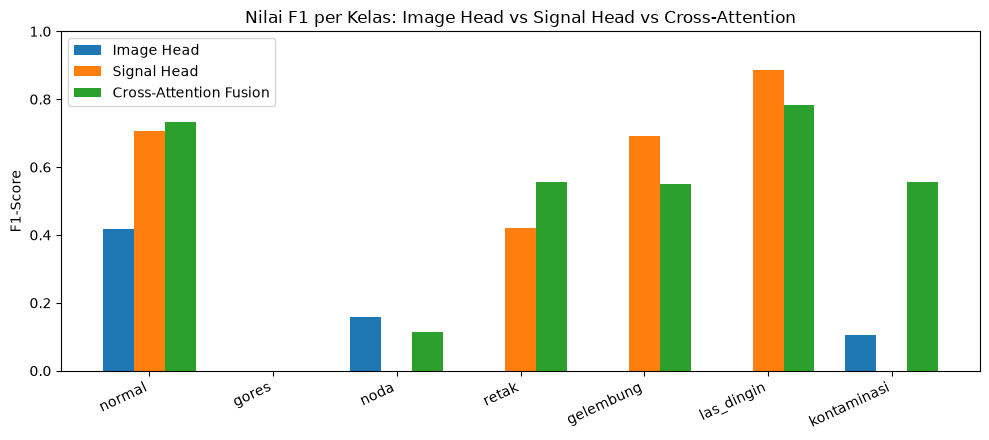

In [41]:
ca_model.eval()
pred_ca = []
with torch.no_grad():
  for b_img, b_sig, _ in val_loader_norm:
    b_img, b_sig = b_img.to(device), b_sig.to(device)
    out_ca = ca_model(b_img, b_sig)
    pred_ca.append(out_ca.argmax(dim=1).cpu().numpy())
pred_ca = np.concatenate(pred_ca)

f1_per_cls_ca = f1_score(
    y_true_val, pred_ca, average=None, labels=range(len(CLASSES)), zero_division=0
)
df_mod_class["F1 Cross-Attention"] = np.round(f1_per_cls_ca, 4)
display(
    df_mod_class[[
        "Kelas",
        "Jumlah Val",
        "F1 Image Head",
        "F1 Signal Head",
        "F1 Late Fusion",
        "F1 Cross-Attention",
        "Modalitas Unggul",
    ]]
)

print(
    "\nClassification Report Detail (Cross-Attention Fusion pada Validation):"
)
print(
    classification_report(
        y_true_val, pred_ca, target_names=CLASSES, digits=4, zero_division=0
    )
)

x = np.arange(len(CLASSES))
w = 0.25

plt.figure(figsize=(10, 4.5))
plt.bar(x - w, f1_per_cls_img, width=w, label="Image Head")
plt.bar(x, f1_per_cls_sig, width=w, label="Signal Head")
plt.bar(x + w, f1_per_cls_ca, width=w, label="Cross-Attention Fusion")
plt.xticks(x, CLASSES, rotation=25, ha="right")
plt.ylabel("F1-Score")
plt.title("Nilai F1 per Kelas: Image Head vs Signal Head vs Cross-Attention")
plt.ylim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

### Identifikasi Kandidat Label Salah (High-Loss Samples pada Train Split)
Kita menghitung loss per sampel pada train_ds_norm menggunakan ca_model dalam mode eval(). Sampel dengan nilai loss terbesar merupakan kandidat label yang berpotensi noisy atau ambigu, dan kita tampilkan ringkasan jumlah kandidat per kelas serta top-10 sampel dengan loss tertinggi.

In [42]:
ca_model.eval()
eval_train_loader = DataLoader(train_ds_norm, batch_size=64, shuffle=False)
ce_per_sample = nn.CrossEntropyLoss(reduction="none")

sample_losses = []
sample_preds = []
sample_confs = []
sample_trues = []

with torch.no_grad():
  for b_img, b_sig, b_y in eval_train_loader:
    b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
    logits = ca_model(b_img, b_sig)
    losses = ce_per_sample(logits, b_y)
    probs = torch.softmax(logits, dim=1)
    top_conf, top_pred = probs.max(dim=1)

    sample_losses.append(losses.cpu().numpy())
    sample_preds.append(top_pred.cpu().numpy())
    sample_confs.append(top_conf.cpu().numpy())
    sample_trues.append(b_y.cpu().numpy())

sample_losses = np.concatenate(sample_losses)
sample_preds = np.concatenate(sample_preds)
sample_confs = np.concatenate(sample_confs)
sample_trues = np.concatenate(sample_trues)

# Ambang batas kandidat label noise: persentil ke-90 loss pada data latih
loss_thresh = np.percentile(sample_losses, 90)
is_noisy_cand = sample_losses >= loss_thresh

df_noise_cand = pd.DataFrame({
    "row_pos": tr_idx,
    "npz_idx": indices_all[tr_idx],
    "label_asli": [CLASSES[i] for i in sample_trues],
    "pred_model": [CLASSES[i] for i in sample_preds],
    "conf_pred": np.round(sample_confs, 4),
    "loss": np.round(sample_losses, 4),
    "kandidat_noise": is_noisy_cand,
})

print(f"Ambang loss persentil ke-90: {loss_thresh:.4f}")
print(
    f"Total kandidat label noise: {is_noisy_cand.sum()} dari"
    f" {len(is_noisy_cand)} sampel ({is_noisy_cand.mean()*100:.2f}%)"
)

print("\nPersentase kandidat noise per kelas asli:")
print(
    (df_noise_cand.groupby("label_asli")["kandidat_noise"].mean() * 100).round(
        2
    )
)

print("\nTop 10 sampel dengan loss tertinggi (kandidat label noise):")
display(
    df_noise_cand.sort_values("loss", ascending=False).head(10).reset_index(drop=True)
)

Ambang loss persentil ke-90: 2.3126
Total kandidat label noise: 320 dari 3200 sampel (10.00%)

Persentase kandidat noise per kelas asli:
label_asli
gelembung      29.26
gores           4.27
kontaminasi    42.04
las_dingin     12.85
noda           25.16
normal          0.38
retak          20.00
Name: kandidat_noise, dtype: float64

Top 10 sampel dengan loss tertinggi (kandidat label noise):


,row_pos,npz_idx,label_asli,pred_model,conf_pred,loss,kandidat_noise
0,16569,16569,las_dingin,normal,0.4092,6.4006,True
1,20804,20804,las_dingin,normal,0.5617,6.0865,True
2,47151,47151,las_dingin,normal,0.5638,6.0493,True
3,23282,23282,las_dingin,normal,0.3995,5.8451,True
4,41931,41931,gelembung,normal,0.5796,5.5395,True
5,24535,24535,las_dingin,normal,0.6668,5.0798,True
6,25619,25619,normal,las_dingin,0.9885,4.9486,True
7,3384,3384,gores,retak,0.9638,4.9141,True
8,36517,36517,retak,normal,0.6719,4.8439,True
9,29436,29436,las_dingin,normal,0.7394,4.7261,True


### Penanganan Label Noise dengan Label Smoothing & Perbandingan Val Macro-F1
Sebagai teknik penanganan label noise, kita menggunakan CrossEntropyLoss(label_smoothing=0.1) agar target probabilitas tidak dipaksa 1.0 secara kaku pada label yang berpotensi noisy atau ambigu, lalu melatih ulang CrossAttentionFusionNet pada split yang sama (8 epoch) dan membandingkan skor Best Val Macro-F1-nya dengan model sebelumnya.

In [43]:
torch.manual_seed(SEED)
ca_model_ls = CrossAttentionFusionNet(
    num_classes=len(CLASSES), embed_dim=128, num_heads=4
).to(device)
criterion_ls = nn.CrossEntropyLoss(label_smoothing=0.1)
criterion_eval = nn.CrossEntropyLoss()

ls_best_f1, ls_best_loss, ls_hist = train_fusion_model(
    ca_model_ls,
    train_loader_norm,
    val_loader_norm,
    criterion_ls,
    device,
    epochs=8,
    lr=1e-3,
    name="Cross-Attn + LabelSmoothing",
)

# Evaluasi konsisten memakai CrossEntropyLoss standar untuk perbandingan val loss
va_loss_std, va_f1_std = evaluate_model(
    ca_model_ls, val_loader_norm, criterion_eval, device, mode="both"
)

df_noise_cmp = pd.DataFrame([
    {
        "Model": "Cross-Attention Fusion (Tanpa Penanganan)",
        "Best Val Macro-F1": round(ca_best_f1, 4),
    },
    {
        "Model": "Cross-Attention + Label Smoothing (0.1)",
        "Best Val Macro-F1": round(max(ls_best_f1, va_f1_std), 4),
    },
])
display(df_noise_cmp)

[Cross-Attn + LabelSmoothing] Epoch  1/8 | Train Loss: 1.6184 | Val Loss: 1.5592 | Val Macro-F1: 0.2201
[Cross-Attn + LabelSmoothing] Epoch  2/8 | Train Loss: 1.5000 | Val Loss: 1.4815 | Val Macro-F1: 0.2056
[Cross-Attn + LabelSmoothing] Epoch  3/8 | Train Loss: 1.4592 | Val Loss: 1.4367 | Val Macro-F1: 0.2622
[Cross-Attn + LabelSmoothing] Epoch  4/8 | Train Loss: 1.4181 | Val Loss: 1.3963 | Val Macro-F1: 0.3726
[Cross-Attn + LabelSmoothing] Epoch  5/8 | Train Loss: 1.3743 | Val Loss: 1.4051 | Val Macro-F1: 0.3517
[Cross-Attn + LabelSmoothing] Epoch  6/8 | Train Loss: 1.3469 | Val Loss: 1.3670 | Val Macro-F1: 0.3919
[Cross-Attn + LabelSmoothing] Epoch  7/8 | Train Loss: 1.3210 | Val Loss: 1.2991 | Val Macro-F1: 0.4438
[Cross-Attn + LabelSmoothing] Epoch  8/8 | Train Loss: 1.2999 | Val Loss: 1.3225 | Val Macro-F1: 0.4870


,Model,Best Val Macro-F1
0,Cross-Attention Fusion (Tanpa Penanganan),0.4704
1,Cross-Attention + Label Smoothing (0.1),0.4870


### Cek Distribusi Lini Produksi & Normalisasi Sensor per Lini (Fit di Train)
 Mengecek kolom lini produksi pada train_meta untuk melihat apakah distribusi kelas atau nilai sensor berbeda antar lini (domain shift). Lalu kita menghitung statistik mean dan std kanal sensor per lini produksi pada tr_idx saja (dengan fallback ke statistik global tr_idx jika suatu lini pada train punya terlalu sedikit sampel), sehingga tiap lini terkalibrasi ke skala referensinya masing-masing.

In [44]:
# Deteksi otomatis nama kolom lini produksi jika ada di train_meta
line_col_candidates = [
    c
    for c in train_meta.columns
    if "lini" in c.lower() or "line" in c.lower() or "domain" in c.lower()
]
line_col = line_col_candidates[0] if len(line_col_candidates) > 0 else None
print("Kolom lini produksi terdeteksi:", line_col)

if line_col is not None:
  lines_all = train_meta[line_col].astype(str).to_numpy()
  print("\nJumlah sampel per lini produksi (seluruh train_meta):")
  print(pd.Series(lines_all).value_counts())

  print("\nRata-rata kanal 0 sensor per lini produksi (raw):")
  ch0_raw = np.nanmean(sigs_all[:, 0, :], axis=1)
  print(pd.Series(ch0_raw).groupby(lines_all).mean().round(4))

  # Fit mean & std per lini produksi HANYA pada tr_idx (anti leakage)
  tr_lines = lines_all[tr_idx]
  tr_npz_pos = indices_all[tr_idx]
  tr_sigs_raw = sigs_all[tr_npz_pos]

  global_mean = np.nanmean(tr_sigs_raw, axis=(0, 2), keepdims=True).astype(
      np.float32
  )
  global_std = np.nanstd(tr_sigs_raw, axis=(0, 2), keepdims=True).astype(
      np.float32
  )
  global_std = np.where(global_std < 1e-6, 1.0, global_std)

  line_stats = {}
  for ln in np.unique(tr_lines):
    mask_ln = tr_lines == ln
    if mask_ln.sum() >= 5:
      m_ln = np.nanmean(tr_sigs_raw[mask_ln], axis=(0, 2), keepdims=True).astype(
          np.float32
      )
      s_ln = np.nanstd(tr_sigs_raw[mask_ln], axis=(0, 2), keepdims=True).astype(
          np.float32
      )
      s_ln = np.where(s_ln < 1e-6, global_std, s_ln)
      line_stats[ln] = (m_ln, s_ln)
    else:
      line_stats[ln] = (global_mean, global_std)

  sigs_line_norm = np.empty_like(sigs_all, dtype=np.float32)
  for i in range(len(sigs_all)):
    ln = lines_all[i]
    m_use, s_use = line_stats.get(ln, (global_mean, global_std))
    sigs_line_norm[i] = (sigs_all[i] - m_use[0]) / s_use[0]
else:
  print(
      "Kolom lini produksi tidak ditemukan di train_meta; menggunakan"
      " normalisasi kanal global (tr_idx) + augmentasi domain."
  )
  lines_all = np.array(["all"] * len(train_meta))
  sigs_line_norm = sigs_norm_all.copy()

Kolom lini produksi terdeteksi: lini

Jumlah sampel per lini produksi (seluruh train_meta):
A    35964
B    12036
Name: count, dtype: int64

Rata-rata kanal 0 sensor per lini produksi (raw):
A    181.119705
B    183.115494
dtype: float32


C:\Users\Fidela Risyunira\AppData\Local\Temp\ipykernel_22684\158417447.py:16: RuntimeWarning: Mean of empty slice
  ch0_raw = np.nanmean(sigs_all[:, 0, :], axis=1)


### Dataset dengan Augmentasi Ringan (Citra & Sensor) + Pengukuran Domain Shift
Saat pelatihan (is_train=True), kita menambahkan augmentasi ringan yang aman untuk inspeksi cacat & sinyal proses:

* Pada citra (1, 64, 64): random horizontal flip (p=0.5) dan small brightness/contrast jitter ringan.

* Pada sinyal (3, 128): small Gaussian noise (sigma=0.03) dan random amplitude scaling ringan (0.95–1.05) agar model lebih tahan terhadap variasi antar lini produksi (domain shift).

Lalu kita melatih ulang CrossAttentionFusionNet dengan label_smoothing=0.1 dan mengukur Best Val Macro-F1 (serta Macro-F1 per lini produksi bila line_col tersedia) untuk dibandingkan dengan hasil sebelumnya (0.4870).

In [45]:
class AugmentedMultimodalDataset(Dataset):

  def __init__(self, row_positions, imgs, sigs, labels, row_to_npz_idx, augment=False, seed=42):
    self.row_positions = np.asarray(row_positions)
    self.imgs = imgs
    self.sigs = sigs
    self.labels = labels
    self.row_to_npz_idx = row_to_npz_idx
    self.augment = augment
    self.rng = np.random.default_rng(seed)

  def __len__(self):
    return len(self.row_positions)

  def __getitem__(self, pos):
    r = self.row_positions[pos]
    npz_i = int(self.row_to_npz_idx[r])

    img = self.imgs[npz_i].astype(np.float32) / 255.0
    if img.ndim == 2:
      img = img[None, :, :]  # (1, 64, 64)
    else:
      img = np.transpose(img, (2, 0, 1))

    sig = np.nan_to_num(self.sigs[npz_i], nan=0.0).astype(np.float32)  # (3, 128)

    if self.augment:
      # Augmentasi citra ringan
      if self.rng.random() < 0.5:
        img = img[:, :, ::-1].copy()
      scale_img = float(self.rng.uniform(0.92, 1.08))
      shift_img = float(self.rng.uniform(-0.04, 0.04))
      img = np.clip(img * scale_img + shift_img, 0.0, 1.0)

      # Augmentasi sinyal ringan (ketahanan variasi lini produksi)
      scale_sig = float(self.rng.uniform(0.95, 1.05))
      noise_sig = self.rng.normal(0.0, 0.03, size=sig.shape).astype(np.float32)
      sig = sig * scale_sig + noise_sig

    label = int(self.labels[r])
    return (
        torch.tensor(img, dtype=torch.float32),
        torch.tensor(sig, dtype=torch.float32),
        torch.tensor(label, dtype=torch.long),
    )


train_ds_dom = AugmentedMultimodalDataset(
    tr_idx, imgs_all, sigs_line_norm, y_all, indices_all, augment=True, seed=SEED
)
val_ds_dom = AugmentedMultimodalDataset(
    va_idx, imgs_all, sigs_line_norm, y_all, indices_all, augment=False, seed=SEED
)

train_loader_dom = DataLoader(train_ds_dom, batch_size=64, shuffle=True)
val_loader_dom = DataLoader(val_ds_dom, batch_size=64, shuffle=False)

torch.manual_seed(SEED)
ca_model_dom = CrossAttentionFusionNet(
    num_classes=len(CLASSES), embed_dim=128, num_heads=4
).to(device)
criterion_dom = nn.CrossEntropyLoss(label_smoothing=0.1)

dom_best_f1, dom_best_loss, dom_hist = train_fusion_model(
    ca_model_dom,
    train_loader_dom,
    val_loader_dom,
    criterion_dom,
    device,
    epochs=8,
    lr=1e-3,
    name="Cross-Attn + DomainNorm/Aug",
)

# Ukur performa per lini produksi pada validation set jika kolom lini tersedia
if line_col is not None:
  ca_model_dom.eval()
  va_preds_dom, va_trues_dom = [], []
  with torch.no_grad():
    for b_img, b_sig, b_y in val_loader_dom:
      b_img, b_sig = b_img.to(device), b_sig.to(device)
      out = ca_model_dom(b_img, b_sig)
      va_preds_dom.append(out.argmax(dim=1).cpu().numpy())
      va_trues_dom.append(b_y.numpy())
  va_preds_dom = np.concatenate(va_preds_dom)
  va_trues_dom = np.concatenate(va_trues_dom)
  va_lines = lines_all[va_idx]

  rows_line_metric = []
  for ln in np.unique(va_lines):
    m = va_lines == ln
    if m.sum() > 0:
      f1_ln = f1_score(
          va_trues_dom[m], va_preds_dom[m], average="macro", zero_division=0
      )
      rows_line_metric.append({
          "Lini Produksi": ln,
          "Jumlah Val": int(m.sum()),
          "Val Macro-F1": round(float(f1_ln), 4),
      })
  print("\nPengukuran Val Macro-F1 per Lini Produksi:")
  display(pd.DataFrame(rows_line_metric))

df_dom_cmp = pd.DataFrame([
    {
        "Eksperimen": "Cross-Attention + Label Smoothing (0.1)",
        "Best Val Macro-F1": round(max(ls_best_f1, va_f1_std), 4),
    },
    {
        "Eksperimen": "Cross-Attention + Domain Norm/Aug + LS",
        "Best Val Macro-F1": round(dom_best_f1, 4),
    },
])
display(df_dom_cmp)

[Cross-Attn + DomainNorm/Aug] Epoch  1/8 | Train Loss: 1.5930 | Val Loss: 1.5814 | Val Macro-F1: 0.2590
[Cross-Attn + DomainNorm/Aug] Epoch  2/8 | Train Loss: 1.4579 | Val Loss: 1.4363 | Val Macro-F1: 0.2866
[Cross-Attn + DomainNorm/Aug] Epoch  3/8 | Train Loss: 1.4265 | Val Loss: 1.4054 | Val Macro-F1: 0.3081
[Cross-Attn + DomainNorm/Aug] Epoch  4/8 | Train Loss: 1.4073 | Val Loss: 1.5059 | Val Macro-F1: 0.3350
[Cross-Attn + DomainNorm/Aug] Epoch  5/8 | Train Loss: 1.3784 | Val Loss: 1.3447 | Val Macro-F1: 0.3467
[Cross-Attn + DomainNorm/Aug] Epoch  6/8 | Train Loss: 1.3558 | Val Loss: 1.3504 | Val Macro-F1: 0.3662
[Cross-Attn + DomainNorm/Aug] Epoch  7/8 | Train Loss: 1.3140 | Val Loss: 1.2969 | Val Macro-F1: 0.4515
[Cross-Attn + DomainNorm/Aug] Epoch  8/8 | Train Loss: 1.2967 | Val Loss: 1.3013 | Val Macro-F1: 0.4673

Pengukuran Val Macro-F1 per Lini Produksi:


,Lini Produksi,Jumlah Val,Val Macro-F1
0,A,608,0.4864
1,B,192,0.3696


,Eksperimen,Best Val Macro-F1
0,Cross-Attention + Label Smoothing (0.1),0.4870
1,Cross-Attention + Domain Norm/Aug + LS,0.4673


### Fungsi Evaluasi Skenario Missing Modality & Pelatihan dengan Modality Dropout
Fungsi evaluate_missing_modality menguji model terlatih pada tiga kondisi (both, missing_img, dan missing_sig) di data validasi. Selanjutnya, CrossAttentionFusionNet (label_smoothing=0.1) dilatih menggunakan modality dropout (p_drop_img=0.2, p_drop_sig=0.2 per sampel saat training) dengan mengosongkan (0.0) salah satu modalitas secara acak—dan memastikan kedua modalitas tidak hilang bersamaan pada sampel yang sama—agar model tidak bergantung penuh pada satu modalitas saja.

In [46]:
def evaluate_missing_modality(model, loader, criterion, device):
  model.eval()
  scenarios = {
      "both": {"preds": [], "trues": [], "loss": 0.0},
      "missing_img": {"preds": [], "trues": [], "loss": 0.0},
      "missing_sig": {"preds": [], "trues": [], "loss": 0.0},
  }
  n_total = len(loader.dataset)

  with torch.no_grad():
    for b_img, b_sig, b_y in loader:
      b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
      bs = len(b_y)

      # 1. Both modalities
      out_both = model(b_img, b_sig)
      scenarios["both"]["loss"] += criterion(out_both, b_y).item() * bs
      scenarios["both"]["preds"].append(out_both.argmax(dim=1).cpu().numpy())
      scenarios["both"]["trues"].append(b_y.cpu().numpy())

      # 2. Missing image (gambar di-nol-kan)
      out_no_img = model(torch.zeros_like(b_img), b_sig)
      scenarios["missing_img"]["loss"] += criterion(out_no_img, b_y).item() * bs
      scenarios["missing_img"]["preds"].append(
          out_no_img.argmax(dim=1).cpu().numpy()
      )
      scenarios["missing_img"]["trues"].append(b_y.cpu().numpy())

      # 3. Missing signal (sensor di-nol-kan)
      out_no_sig = model(b_img, torch.zeros_like(b_sig))
      scenarios["missing_sig"]["loss"] += criterion(out_no_sig, b_y).item() * bs
      scenarios["missing_sig"]["preds"].append(
          out_no_sig.argmax(dim=1).cpu().numpy()
      )
      scenarios["missing_sig"]["trues"].append(b_y.cpu().numpy())

  results = {}
  for k, v in scenarios.items():
    y_t = np.concatenate(v["trues"])
    y_p = np.concatenate(v["preds"])
    f1 = f1_score(y_t, y_p, average="macro", zero_division=0)
    results[k] = {
        "val_loss": round(v["loss"] / n_total, 4),
        "val_macro_f1": round(float(f1), 4),
    }
  return results


def train_with_modality_dropout(
    model,
    train_loader,
    val_loader,
    device,
    epochs=8,
    lr=1e-3,
    p_drop_img=0.2,
    p_drop_sig=0.2,
    seed=42,
):
  rng = np.random.default_rng(seed)
  opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
  crit = nn.CrossEntropyLoss(label_smoothing=0.1)
  best_both_f1 = 0.0

  for ep in range(1, epochs + 1):
    model.train()
    tr_loss = 0.0
    for b_img, b_sig, b_y in train_loader:
      b_img, b_sig, b_y = b_img.to(device), b_sig.to(device), b_y.to(device)
      bs = len(b_y)

      img_in = b_img.clone()
      sig_in = b_sig.clone()

      for i in range(bs):
        drop_i = rng.random() < p_drop_img
        drop_s = rng.random() < p_drop_sig
        # Pastikan tidak keduanya hilang bersamaan pada sampel yang sama
        if drop_i and drop_s:
          if rng.random() < 0.5:
            drop_i = False
          else:
            drop_s = False
        if drop_i:
          img_in[i].zero_()
        if drop_s:
          sig_in[i].zero_()

      opt.zero_grad()
      out = model(img_in, sig_in)
      loss = crit(out, b_y)
      loss.backward()
      opt.step()
      tr_loss += loss.item() * bs

    tr_loss /= len(train_loader.dataset)
    res_ep = evaluate_missing_modality(
        model, val_loader, nn.CrossEntropyLoss(), device
    )
    best_both_f1 = max(best_both_f1, res_ep["both"]["val_macro_f1"])
    print(
        f"[ModDrop] Epoch {ep:2d}/{epochs} | Train Loss: {tr_loss:.4f} | Both"
        f" F1: {res_ep['both']['val_macro_f1']:.4f} | No-Img F1:"
        f" {res_ep['missing_img']['val_macro_f1']:.4f} | No-Sig F1:"
        f" {res_ep['missing_sig']['val_macro_f1']:.4f}"
    )

  return best_both_f1

### Bandingkan Ketahanan: Tanpa Modality Dropout vs Dengan Modality Dropout
Performa ketahanan ca_model_ls (dilatih tanpa modality dropout) dan ca_model_md (dilatih dengan modality dropout) dibandingkan pada ketiga skenario (both, missing_img, dan missing_sig) di data validasi melalui tabel ringkasan.

In [47]:
res_no_md = evaluate_missing_modality(
    ca_model_ls, val_loader_norm, nn.CrossEntropyLoss(), device
)

torch.manual_seed(SEED)
ca_model_md = CrossAttentionFusionNet(
    num_classes=len(CLASSES), embed_dim=128, num_heads=4
).to(device)
_ = train_with_modality_dropout(
    ca_model_md,
    train_loader_norm,
    val_loader_norm,
    device,
    epochs=8,
    lr=1e-3,
    p_drop_img=0.2,
    p_drop_sig=0.2,
    seed=SEED,
)
res_with_md = evaluate_missing_modality(
    ca_model_md, val_loader_norm, nn.CrossEntropyLoss(), device
)

df_md_cmp = pd.DataFrame([
    {
        "Model": "Tanpa Modality Dropout",
        "Both Modalities F1": res_no_md["both"]["val_macro_f1"],
        "Missing Image F1": res_no_md["missing_img"]["val_macro_f1"],
        "Missing Signal F1": res_no_md["missing_sig"]["val_macro_f1"],
    },
    {
        "Model": "Dengan Modality Dropout (0.2)",
        "Both Modalities F1": res_with_md["both"]["val_macro_f1"],
        "Missing Image F1": res_with_md["missing_img"]["val_macro_f1"],
        "Missing Signal F1": res_with_md["missing_sig"]["val_macro_f1"],
    },
])
display(df_md_cmp)

[ModDrop] Epoch  1/8 | Train Loss: 1.6443 | Both F1: 0.2251 | No-Img F1: 0.1636 | No-Sig F1: 0.0949
[ModDrop] Epoch  2/8 | Train Loss: 1.5477 | Both F1: 0.2073 | No-Img F1: 0.2098 | No-Sig F1: 0.0949
[ModDrop] Epoch  3/8 | Train Loss: 1.5243 | Both F1: 0.2317 | No-Img F1: 0.2273 | No-Sig F1: 0.0949
[ModDrop] Epoch  4/8 | Train Loss: 1.5055 | Both F1: 0.2419 | No-Img F1: 0.2485 | No-Sig F1: 0.0949
[ModDrop] Epoch  5/8 | Train Loss: 1.4912 | Both F1: 0.2248 | No-Img F1: 0.2457 | No-Sig F1: 0.0949
[ModDrop] Epoch  6/8 | Train Loss: 1.4743 | Both F1: 0.3053 | No-Img F1: 0.2646 | No-Sig F1: 0.0949
[ModDrop] Epoch  7/8 | Train Loss: 1.4610 | Both F1: 0.2960 | No-Img F1: 0.3186 | No-Sig F1: 0.0949
[ModDrop] Epoch  8/8 | Train Loss: 1.4291 | Both F1: 0.3618 | No-Img F1: 0.3559 | No-Sig F1: 0.0949


,Model,Both Modalities F1,Missing Image F1,Missing Signal F1
0,Tanpa Modality Dropout,0.4870,0.1789,0.1203
1,Dengan Modality Dropout (0.2),0.3618,0.3559,0.0949


### Pelatihan Multi-Seed (mean ± std Val Macro-F1)
Model CrossAttentionFusionNet dengan CrossEntropyLoss(label_smoothing=0.1) dilatih pada split yang sama menggunakan tiga random seed berbeda ([42, 123, 2026]) selama 8 epoch per seed. Skor terbaik (Best Val Macro-F1) tiap seed dicatat, lalu dihitung rata-rata (mean) dan standar deviasi (std) untuk mengukur stabilitas performa lintas inisialisasi.

In [48]:
SEEDS_EVAL = [42, 123, 2026]
seed_results = []

for s in SEEDS_EVAL:
  np.random.seed(s)
  torch.manual_seed(s)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(s)

  model_s = CrossAttentionFusionNet(
      num_classes=len(CLASSES), embed_dim=128, num_heads=4
  ).to(device)
  crit_s = nn.CrossEntropyLoss(label_smoothing=0.1)

  best_f1_s, best_loss_s, _ = train_fusion_model(
      model_s,
      train_loader_norm,
      val_loader_norm,
      crit_s,
      device,
      epochs=8,
      lr=1e-3,
      name=f"Seed {s}",
  )
  seed_results.append(
      {"Seed": s, "Best Val Macro-F1": round(float(best_f1_s), 4)}
  )

df_seeds = pd.DataFrame(seed_results)
mean_f1 = df_seeds["Best Val Macro-F1"].mean()
std_f1 = df_seeds["Best Val Macro-F1"].std(ddof=1)

display(df_seeds)
print(
    f"\nRingkasan Multi-Seed (n={len(SEEDS_EVAL)}): Val Macro-F1 = {mean_f1:.4f}"
    f" ± {std_f1:.4f}"
)

[Seed 42] Epoch  1/8 | Train Loss: 1.6184 | Val Loss: 1.5592 | Val Macro-F1: 0.2201
[Seed 42] Epoch  2/8 | Train Loss: 1.5000 | Val Loss: 1.4815 | Val Macro-F1: 0.2056
[Seed 42] Epoch  3/8 | Train Loss: 1.4592 | Val Loss: 1.4367 | Val Macro-F1: 0.2622
[Seed 42] Epoch  4/8 | Train Loss: 1.4181 | Val Loss: 1.3963 | Val Macro-F1: 0.3726
[Seed 42] Epoch  5/8 | Train Loss: 1.3743 | Val Loss: 1.4051 | Val Macro-F1: 0.3517
[Seed 42] Epoch  6/8 | Train Loss: 1.3469 | Val Loss: 1.3670 | Val Macro-F1: 0.3919
[Seed 42] Epoch  7/8 | Train Loss: 1.3210 | Val Loss: 1.2991 | Val Macro-F1: 0.4438
[Seed 42] Epoch  8/8 | Train Loss: 1.2999 | Val Loss: 1.3225 | Val Macro-F1: 0.4870
[Seed 123] Epoch  1/8 | Train Loss: 1.6106 | Val Loss: 1.5424 | Val Macro-F1: 0.1971
[Seed 123] Epoch  2/8 | Train Loss: 1.4792 | Val Loss: 1.4561 | Val Macro-F1: 0.2410
[Seed 123] Epoch  3/8 | Train Loss: 1.4220 | Val Loss: 1.4222 | Val Macro-F1: 0.3476
[Seed 123] Epoch  4/8 | Train Loss: 1.3869 | Val Loss: 1.3657 | Val Macro

,Seed,Best Val Macro-F1
0,42,0.4870
1,123,0.4619
2,2026,0.4448



Ringkasan Multi-Seed (n=3): Val Macro-F1 = 0.4646 ± 0.0212


### Inferensi Data Uji & Ekspor prediksi_klasifikasi.csv
Data uji (test) dimuat dan dinormalisasi menggunakan parameter sig_mean dan sig_std yang telah dihitung dari data latih (tr_idx). Model terbaik dari eksperimen multi-seed (best_seed_model, atau model CrossAttentionFusionNet yang dilatih pada tr_idx dengan label_smoothing=0.1) menjalankan inferensi tanpa gradien (torch.no_grad()), memetakan indeks prediksi ke label string CLASSES, lalu menyusun DataFrame dengan kolom id_unit dan kelas dan menyimpannya ke prediksi_klasifikasi.csv.

In [50]:
import glob, os
from pathlib import Path

# 1. Cari metadata test (jika ada)
test_meta_df = None
for cand_name in ["test_meta", "df_test", "meta_test"]:
  if cand_name in globals() and isinstance(globals()[cand_name], pd.DataFrame):
    test_meta_df = globals()[cand_name].copy()
    break

if test_meta_df is None:
  for p in sorted(
      glob.glob("**/test*meta*.csv", recursive=True)
      + glob.glob("**/*test*.csv", recursive=True)
  ):
    if "prediksi" not in os.path.basename(p).lower():
      test_meta_df = pd.read_csv(p)
      print("Memuat test metadata dari:", p)
      break

# 2. Cari tensor gambar & sinyal test
test_imgs_arr, test_sigs_arr, test_indices_arr = None, None, None
for obj_name in ["npz_test", "data_test", "test_npz"]:
  if obj_name in globals():
    obj = globals()[obj_name]
    if isinstance(obj, dict) or hasattr(obj, "files"):
      keys = list(obj.keys()) if isinstance(obj, dict) else list(obj.files)
      img_k = next((k for k in keys if "img" in k.lower() or "gambar" in k.lower()), None)
      sig_k = next((k for k in keys if "sig" in k.lower() or "sensor" in k.lower() or "vib" in k.lower()), None)
      idx_k = next((k for k in keys if "idx" in k.lower() or "index" in k.lower() or "id" in k.lower()), None)
      if img_k:
        test_imgs_arr = obj[img_k]
      if sig_k:
        test_sigs_arr = obj[sig_k]
      if idx_k:
        test_indices_arr = obj[idx_k]
      break

if test_imgs_arr is None or test_sigs_arr is None:
  for p in sorted(glob.glob("**/*test*.npz", recursive=True)):
    npz_t = np.load(p, allow_pickle=True)
    keys = list(npz_t.files)
    img_k = next((k for k in keys if "img" in k.lower() or "gambar" in k.lower()), None)
    sig_k = next((k for k in keys if "sig" in k.lower() or "sensor" in k.lower() or "vib" in k.lower()), None)
    idx_k = next((k for k in keys if "idx" in k.lower() or "index" in k.lower()), None)
    if img_k and sig_k:
      test_imgs_arr = npz_t[img_k]
      test_sigs_arr = npz_t[sig_k]
      if idx_k:
        test_indices_arr = npz_t[idx_k]
      print("Memuat test tensor dari:", p)
      break

assert test_imgs_arr is not None and test_sigs_arr is not None, (
    "Data test belum ketemu otomatis. Cek nama variabel atau path file test."
)

# 3. Normalisasi sinyal test memakai mean & std dari tr_idx
test_sigs_norm = (
    (np.asarray(test_sigs_arr, dtype=np.float32) - sig_mean) / sig_std
).astype(np.float32)
test_imgs_arr = np.asarray(test_imgs_arr)

n_test = len(test_imgs_arr)
if test_indices_arr is None:
  test_indices_arr = np.arange(n_test)

class MultimodalTestDataset(Dataset):
  def __init__(self, imgs, sigs, row_to_npz_idx):
    self.imgs = imgs
    self.sigs = sigs
    self.row_to_npz_idx = row_to_npz_idx

  def __len__(self):
    return len(self.row_to_npz_idx)

  def __getitem__(self, pos):
    npz_i = int(self.row_to_npz_idx[pos])
    img = self.imgs[npz_i].astype(np.float32) / 255.0
    if img.ndim == 2:
      img = img[None, :, :]
    else:
      img = np.transpose(img, (2, 0, 1))
    sig = np.nan_to_num(self.sigs[npz_i], nan=0.0).astype(np.float32)
    return torch.tensor(img, dtype=torch.float32), torch.tensor(sig, dtype=torch.float32)

test_ds = MultimodalTestDataset(test_imgs_arr, test_sigs_norm, test_indices_arr)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# 4. Inferensi memakai model terbaik yang sudah dilatih
infer_model = (
    model_s
    if "model_s" in globals()
    else (ca_model_ls if "ca_model_ls" in globals() else ca_model)
)
infer_model.eval()

test_preds_idx = []
with torch.no_grad():
  for b_img, b_sig in test_loader:
    b_img, b_sig = b_img.to(device), b_sig.to(device)
    logits = infer_model(b_img, b_sig)
    test_preds_idx.append(logits.argmax(dim=1).cpu().numpy())

test_preds_idx = np.concatenate(test_preds_idx)
test_preds_label = [CLASSES[int(i)] for i in test_preds_idx]

if test_meta_df is not None and len(test_meta_df) == len(test_preds_label):
  id_col = next(
      (
          c
          for c in test_meta_df.columns
          if "id_unit" in c.lower() or "unit" in c.lower() or c.lower() == "id"
      ),
      None,
  )
  unit_ids = (
      test_meta_df[id_col].tolist()
      if id_col is not None
      else [f"unit_{i}" for i in range(len(test_preds_label))]
  )
else:
  unit_ids = [f"unit_{i}" for i in range(len(test_preds_label))]

df_sub = pd.DataFrame({
    "id_unit": unit_ids,
    "kelas": test_preds_label,
})

# 5. Simpan langsung ke path lengkap dan verifikasi
target_csv = Path(
    r"C:\Users\Fidela Risyunira\Documents\Tingkat4\DL\UTS DL\UTS-DL-Kelompok8\prediksi_klasifikasi.csv"
)
target_csv.parent.mkdir(parents=True, exist_ok=True)
df_sub.to_csv(target_csv, index=False)

check_df = pd.read_csv(target_csv)
print("File berhasil disimpan ke:", target_csv)
print("Ukuran file (bytes):", target_csv.stat().st_size)
print("Jumlah baris & kolom:", check_df.shape)
print("Nama kolom:", list(check_df.columns))
print("Jumlah missing value:", int(check_df.isna().sum().sum()))
print("\nDistribusi prediksi kelas:")
print(check_df["kelas"].value_counts())
display(check_df.head(10))

File berhasil disimpan ke: C:\Users\Fidela Risyunira\Documents\Tingkat4\DL\UTS DL\UTS-DL-Kelompok8\prediksi_klasifikasi.csv
Ukuran file (bytes): 262197
Jumlah baris & kolom: (16000, 2)
Nama kolom: ['id_unit', 'kelas']
Jumlah missing value: 0

Distribusi prediksi kelas:
kelas
normal         13989
las_dingin      1117
retak            323
gelembung        311
kontaminasi      232
noda              28
Name: count, dtype: int64


,id_unit,kelas
0,U412019,normal
1,U929275,normal
2,U845264,normal
3,U382231,normal
4,U156089,normal
5,U563952,normal
6,U922240,normal
7,U494185,normal
8,U489550,normal
9,U853085,retak


## Ringkasan Tugas 1: Klasifikasi Multimodal Cacat Produk

**Data.** 48.000 sampel latih dan 16.000 sampel uji, masing-masing berisi gambar 64×64 dan sensor 3×128 (suhu, getaran, arus). Ada 7 kelas dan distribusinya timpang: normal 49,77%, kontaminasi hanya 4,91%. Sekitar 8% sensor hilang (NaN), merata di semua kelas dan lini. Proporsi lini produksi berbeda jauh: data latih 75% lini A, data uji 60% lini B. Intensitas gambar juga berbeda (rata-rata A 139,8 vs B 111,7), jadi ada indikasi domain shift.

**Setup eksperimen.** Seluruh eksperimen memakai subset stratified 4.000 sampel (3.200 latih, 800 validasi), 8 epoch. Sensor distandardisasi per kanal dengan statistik dari data latih saja, dan NaN diisi 0.

**Hasil (Val Macro-F1 terbaik):**

| Model | Macro-F1 |
|---|---|
| Image-only | 0,1074 |
| Signal-only | 0,1855 |
| CNN + Conv1D-GRU (concat) | 0,4133 |
| Late Fusion | 0,4178 |
| Cross-Attention Fusion | 0,4704 |
| Cross-Attention + Label Smoothing 0,1 | 0,4870 |
| Cross-Attention + Norm per lini + Augmentasi | 0,4673 |
| Multi-seed (42, 123, 2026), Cross-Attn + LS | 0,4646 ± 0,0212 |

**Temuan utama:**
1. Fusi dua modalitas jauh lebih baik daripada satu modalitas, dan Cross-Attention paling baik di antara strategi fusi.
2. Sensor lebih kuat untuk las_dingin (F1 0,89), gelembung, dan retak. Gambar sedikit lebih unggul untuk noda dan kontaminasi, tetapi skornya tetap rendah. Kelas gores belum terdeteksi sama sekali (F1 0) pada semua model.
3. Label noise: dengan loss persentil ke-90, kandidat label salah paling banyak ada di kontaminasi (42%), gelembung (29%), dan noda (25%). Label smoothing menaikkan F1 dari 0,4704 ke 0,4870.
4. Normalisasi per lini dan augmentasi tidak menaikkan skor (0,4673), dan F1 lini B (0,3696) lebih rendah daripada lini A (0,4864), sehingga domain shift masih tersisa.
5. Modality dropout membuat model lebih tahan saat gambar hilang (F1 0,1789 naik ke 0,3559), tetapi F1 saat kedua modalitas ada turun (0,4870 turun ke 0,3618). Saat sensor hilang, model tetap lemah (0,0949).

**Keluaran.** prediksi_klasifikasi.csv berisi 16.000 baris (id_unit, kelas) tanpa missing value.

**Keterbatasan.** Skor di atas dihitung pada subset kecil dan belum memakai seluruh 48.000 data. Sanity check overfit satu batch hanya mencapai akurasi 43,75% (target 100%). Prediksi uji sangat condong ke normal (13.989 dari 16.000), noda hanya 28, dan gores tidak diprediksi sama sekali. Langkah berikutnya: latih pada data penuh, tangani ketimpangan kelas (class weight/oversampling), dan perkuat pengenalan gores dan noda.